# Model 3: Static MFCC + Random Forest (baseline)

Each clip is turned into 40 MFCCs averaged over time, so all timing information is lost. This is
the simple baseline that Models 1 and 2 are compared against.

Classes: Prolongation, Block, SoundRep, WordRep, Interjection, NoStutteredWords. Split: `SEP28k-E`.
Code shared with the other notebooks (labels, clip extraction, evaluation) is in `common.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

%run common.ipynb  # shared settings and helper functions

## 1. Labels

A clip's label is whichever class got the most annotator votes, counting only classes with at
least 2 of 3 votes. Clips with audio-quality flags or from episodes that couldn't be downloaded
are dropped (see `load_clips` in `common.ipynb`).

In [2]:
clips = load_clips()
train_df, dev_df, test_df = split_clips(clips)

print(f"Usable clips: {len(clips)}")
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")
print_class_counts(clips["label"], "\nClass distribution (all splits):")

Usable clips: 14930
Train: 8708, Dev: 3001, Test: 3221

Class distribution (all splits):
  0 Prolongation: 1255
  1 Block: 1415
  2 SoundRep: 921
  3 WordRep: 1707
  4 Interjection: 2623
  5 NoStutteredWords: 7009


## 2. Class imbalance

There are far more NoStutteredWords clips than any stutter type. Three ways of dealing with this
are compared on the dev set in section 4, and the best one is kept:

- **Class-weighted**: full training set, with `class_weight="balanced"` in the forest
- **Undersampling**: NoStutteredWords cut down to the average size of the stutter classes
- **Oversampling**: each stutter class resampled (with replacement) up to the NoStutteredWords size

Only the training set is resampled. Dev and test keep their natural distribution.

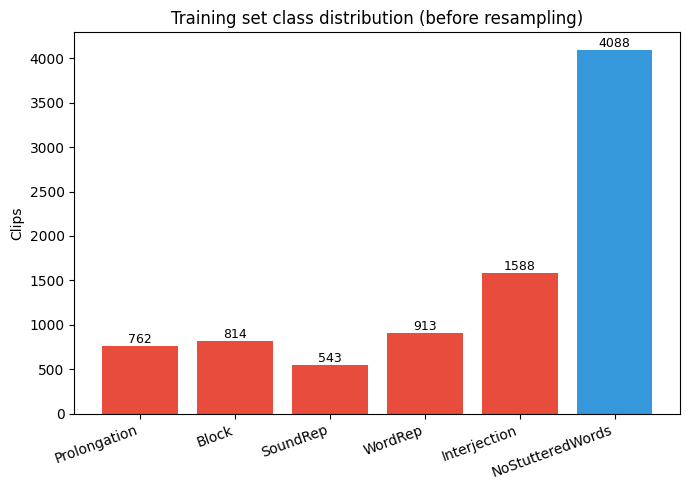

In [3]:
train_counts = np.bincount(train_df["label"], minlength=len(CLASS_NAMES))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(CLASS_NAMES, train_counts, color=["#e74c3c"] * 5 + ["#3498db"])
ax.bar_label(bars, fontsize=9)
ax.set_title("Training set class distribution (before resampling)")
ax.set_ylabel("Clips")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 3. MFCC features

Each clip is cut out of its episode WAV using the `Start`/`Stop` sample indices and padded or cut
to 3 seconds. 40 MFCCs (25 ms window, 10 ms hop) are averaged over time, giving one 40-number
vector per clip. Features are cached in `feature_cache/` after the first run.

In [4]:
def mfcc_means(df, name):
    def build():
        X = np.array([mfcc(clip).mean(axis=1) for clip in sep28k_clips(df, name)])
        return X, df["label"].to_numpy()
    return cached(f"X_{name}_v2", f"y_{name}_v2", build)


X_train_full, y_train_full = mfcc_means(train_df, "train_full")
X_dev, y_dev = mfcc_means(dev_df, "dev")
X_test, y_test = mfcc_means(test_df, "test")

print(f"\nTrain: {X_train_full.shape}, Dev: {X_dev.shape}, Test: {X_test.shape}")

X_train_full_v2: loaded from cache
X_dev_v2: loaded from cache
X_test_v2: loaded from cache

Train: (8708, 40), Dev: (3001, 40), Test: (3221, 40)


## 4. Choosing the imbalance strategy on dev

One forest is trained per strategy and scored by macro F1 on dev. The forest settings (including
`class_weight="balanced"`) are the same for all three, so only the resampling changes. The best
forest is used for the rest of the notebook.

In [5]:
strategies = imbalance_strategies(y_train_full)
forests, strategy_dev_f1 = {}, {}

for name, idx in strategies.items():
    forest = make_random_forest().fit(X_train_full[idx], y_train_full[idx])
    forests[name] = forest
    strategy_dev_f1[name] = macro_f1(y_dev, forest.predict(X_dev))
    print(f"{name:15s} n_train={len(idx):6d}  dev macro F1={strategy_dev_f1[name]:.4f}")

best_strategy = max(strategy_dev_f1, key=strategy_dev_f1.get)
rf = forests[best_strategy]
print(f"\nBest strategy on dev: {best_strategy}")

class_weighted  n_train=  8708  dev macro F1=0.1152


undersampling   n_train=  5544  dev macro F1=0.1554


oversampling    n_train= 24528  dev macro F1=0.1358

Best strategy on dev: undersampling


## 5. Evaluate

=== Dev ===
                  precision    recall  f1-score   support

    Prolongation       0.15      0.12      0.13       251
           Block       0.15      0.15      0.15       291
        SoundRep       0.05      0.01      0.02       200
         WordRep       0.12      0.13      0.13       349
    Interjection       0.19      0.65      0.29       503
NoStutteredWords       0.52      0.14      0.22      1407

        accuracy                           0.21      3001
       macro avg       0.20      0.20      0.16      3001
    weighted avg       0.32      0.21      0.19      3001

Macro AUC-ROC (OVR): 0.5650


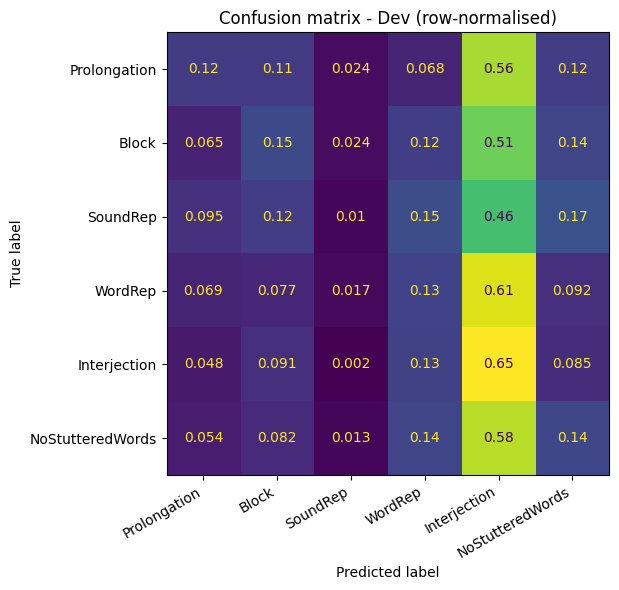

In [6]:
def evaluate(X, y, title):
    report(y, rf.predict(X), rf.predict_proba(X), title)


evaluate(X_dev, y_dev, "Dev")

=== Test ===
                  precision    recall  f1-score   support

    Prolongation       0.13      0.07      0.09       242
           Block       0.18      0.16      0.17       310
        SoundRep       0.07      0.01      0.02       178
         WordRep       0.13      0.11      0.12       445
    Interjection       0.18      0.68      0.29       532
NoStutteredWords       0.56      0.14      0.23      1514

        accuracy                           0.22      3221
       macro avg       0.21      0.20      0.15      3221
    weighted avg       0.34      0.22      0.20      3221

Macro AUC-ROC (OVR): 0.5669


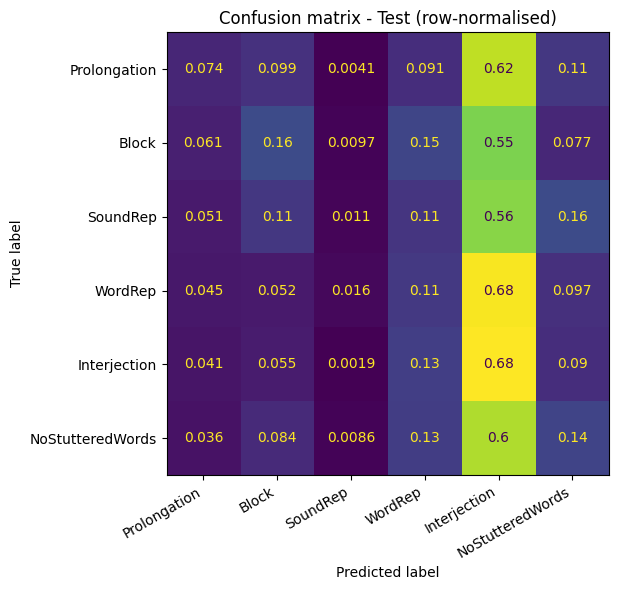

In [7]:
evaluate(X_test, y_test, "Test")

## 6. Cross-corpus test on UCLASS

The UCLASS features come from `UCLASS_Preprocessing.ipynb` and use the same MFCC settings and label
order. No UCLASS clip was used for training or for choosing the strategy, so this tests how well a
model trained on adult podcast speech transfers to a clinical corpus with children in it.

UCLASS: 4712 clips
age_group
Adult (18+)    3625
Child (<18)    1087
Name: count, dtype: int64


=== UCLASS ===
                  precision    recall  f1-score   support

    Prolongation       0.09      0.04      0.05       443
           Block       0.17      0.05      0.08      1132
        SoundRep       0.10      0.05      0.06       720
         WordRep       0.05      0.15      0.08        54
    Interjection       0.03      0.64      0.05       141
NoStutteredWords       0.21      0.04      0.07      2222

        accuracy                           0.06      4712
       macro avg       0.11      0.16      0.06      4712
    weighted avg       0.17      0.06      0.07      4712

Macro AUC-ROC (OVR): 0.4466


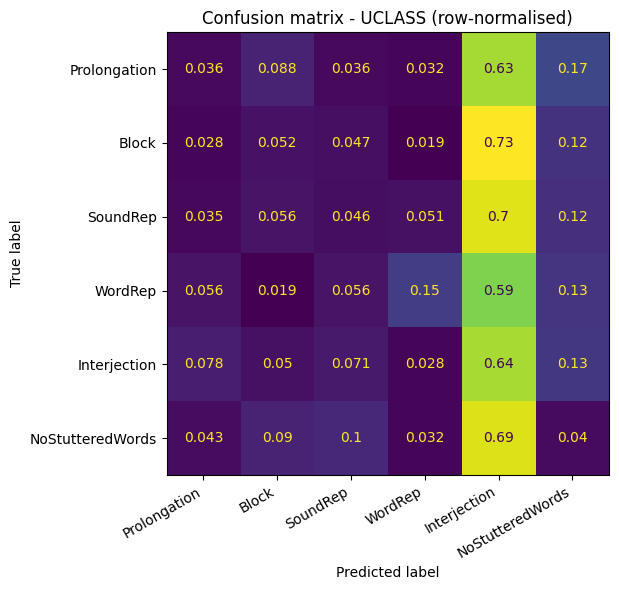

In [8]:
uclass_meta = load_uclass_meta()
X_uclass = np.load(CACHE_DIR / "X_uclass_v1.npy")
y_uclass = np.load(CACHE_DIR / "y_uclass_v1.npy")
assert len(uclass_meta) == len(y_uclass), "rerun UCLASS_Preprocessing.ipynb"

print(f"UCLASS: {len(y_uclass)} clips")
print(uclass_meta["age_group"].value_counts())
evaluate(X_uclass, y_uclass, "UCLASS")

## 7. Child vs adult

The child subgroup has fewer than 20 speakers, so macro F1 is given with a 95% bootstrap confidence
interval (2000 resamples). The child results should be treated as exploratory.

In [9]:
age_group_report(y_uclass, rf.predict(X_uclass), uclass_meta)


=== UCLASS - Child (<18) (n=1087) ===


                  precision    recall  f1-score   support

    Prolongation       0.11      0.06      0.08       150
           Block       0.26      0.14      0.18       270
        SoundRep       0.12      0.10      0.11       236
         WordRep       0.08      0.11      0.09        38
    Interjection       0.08      0.50      0.14        70
NoStutteredWords       0.17      0.10      0.12       323

        accuracy                           0.13      1087
       macro avg       0.14      0.17      0.12      1087
    weighted avg       0.16      0.13      0.13      1087



Macro F1: 0.1205  (95% bootstrap CI: [0.0998, 0.1438])

=== UCLASS - Adult (18+) (n=3625) ===
                  precision    recall  f1-score   support

    Prolongation       0.07      0.02      0.04       293
           Block       0.11      0.03      0.04       862
        SoundRep       0.06      0.02      0.03       484
         WordRep       0.04      0.25      0.07        16
    Interjection       0.02      0.77      0.04        71
NoStutteredWords       0.25      0.03      0.05      1899

        accuracy                           0.04      3625
       macro avg       0.09      0.19      0.04      3625
    weighted avg       0.17      0.04      0.05      3625



Macro F1: 0.0438  (95% bootstrap CI: [0.0320, 0.0566])


## 8. Save predictions

Used by `Results_Summary.ipynb` to compare the three models without retraining.

In [10]:
splits = {name: (y, rf.predict(X), rf.predict_proba(X))
          for name, X, y in [("dev", X_dev, y_dev), ("test", X_test, y_test), ("uclass", X_uclass, y_uclass)]}
save_predictions("model3_static_rf_preds.npz", splits, strategy_dev_f1, best_strategy)

Saved results\model3_static_rf_preds.npz